# Experiment 10: Intelligent Decision Support System

**Aim:** Build a decision-support system using rule-based reasoning, learning from examples, and ethical AI evaluation.

**Application:** Loan approval (Approve / Review / Reject)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass, replace
from typing import Callable

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, ConfusionMatrixDisplay)

SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option("display.precision", 3)

## Dataset
Synthetic loan applicants. Past human decisions are simulated with a small **hidden bias against female applicants**, so the fairness audit has something to detect. `merit` is the bias-free decision, used only for auditing.

In [2]:
N = 2000

gender = rng.choice(["Male", "Female"], N)
region = rng.choice(["Urban", "Rural"], N, p=[0.6, 0.4])
age = rng.integers(21, 66, N)
age_group = np.where(age < 30, "<30", np.where(age <= 45, "30-45", "46+"))

income = rng.lognormal(np.log(7), 0.4, N) * np.where(region == "Rural", 0.8, 1.0)  # lakh INR / year
credit_score = rng.normal(680, 70, N).clip(300, 850).round()
debt_ratio = rng.beta(2, 5, N).clip(0.05, 0.8)
employment_years = (rng.uniform(0, 1, N) * (age - 21)).round(1)
loan_amount = income * rng.uniform(0.5, 4.5, N)                                   # lakh INR
collateral = rng.binomial(1, 0.4, N)
past_default = rng.binomial(1, 0.1, N)

df = pd.DataFrame({
    "gender": gender, "age_group": age_group, "region": region,
    "income": income.round(2), "credit_score": credit_score,
    "debt_ratio": debt_ratio.round(3), "employment_years": employment_years,
    "loan_amount": loan_amount.round(2), "collateral": collateral,
    "past_default": past_default,
})
df["loan_to_income"] = (df["loan_amount"] / df["income"]).round(3)
df["is_female"] = (df["gender"] == "Female").astype(int)

# Simulated human reviewer
z_fair = (0.4
          + 0.02 * (df["credit_score"] - 650)
          + 6 * (0.35 - df["debt_ratio"])
          - 0.6 * df["loan_to_income"]
          + 0.08 * df["employment_years"].clip(upper=10)
          + 0.15 * (df["income"] - 7)
          - 1.5 * df["past_default"]
          + 0.7 * df["collateral"]
          + rng.normal(0, 0.5, N))
z_human = z_fair - 0.7 * df["is_female"]               # hidden reviewer bias

df["merit"] = (z_fair > 0).astype(int)                 # audit label (bias-free)
df["human_decision"] = (z_human > 0).astype(int)       # 1 = Approve, 0 = Reject

print("Human approval rate:", round(df["human_decision"].mean(), 3))
df.head()

Human approval rate: 0.556


,gender,age_group,region,income,credit_score,debt_ratio,employment_years,loan_amount,collateral,past_default,loan_to_income,is_female,merit,human_decision
0,Male,46+,Urban,4.62,730.0,0.089,7.7,8.79,1,0,1.903,0,1,1
1,Female,46+,Urban,3.85,776.0,0.354,10.0,15.88,0,0,4.125,1,1,1
2,Female,46+,Urban,12.02,794.0,0.135,18.2,22.36,0,0,1.860,1,1,1
3,Male,46+,Urban,18.45,694.0,0.347,11.2,81.36,0,0,4.410,0,1,1
4,Male,30-45,Rural,4.63,720.0,0.210,8.9,19.65,0,0,4.244,0,1,1


## Exercise 1: Expert System
Knowledge base = rules + derived facts. Inference engine = forward chaining, then conflict resolution (highest priority wins; ties go to the safer decision).

In [3]:
@dataclass
class Rule:
    id: str
    text: str            # human-readable condition (used for explanations)
    cond: Callable       # facts -> bool
    decision: str
    priority: int


# Derived facts, inferred from raw facts before the rules fire
DERIVED = {
    "loan_to_income": lambda f: f["loan_amount"] / f["income"],
    "stable_job":     lambda f: f["employment_years"] >= 2,
}

RULES = [
    Rule("R1", "past_default AND credit_score < 650",
         lambda f: f["past_default"] == 1 and f["credit_score"] < 650, "Reject", 100),
    Rule("R2", "credit_score < 580",
         lambda f: f["credit_score"] < 580, "Reject", 100),
    Rule("R3", "debt_ratio > 0.50",
         lambda f: f["debt_ratio"] > 0.50, "Reject", 90),
    Rule("R4", "loan_to_income > 4",
         lambda f: f["loan_to_income"] > 4, "Reject", 90),
    Rule("R5", "past_default AND credit_score >= 650",
         lambda f: f["past_default"] == 1 and f["credit_score"] >= 650, "Review", 60),
    Rule("R6", "credit_score >= 720 AND debt_ratio <= 0.35 AND loan_to_income <= 3",
         lambda f: f["credit_score"] >= 720 and f["debt_ratio"] <= 0.35 and f["loan_to_income"] <= 3,
         "Approve", 50),
    Rule("R7", "credit_score >= 650 AND stable_job AND debt_ratio <= 0.40 AND loan_to_income <= 3",
         lambda f: f["credit_score"] >= 650 and f["stable_job"] and f["debt_ratio"] <= 0.40
                   and f["loan_to_income"] <= 3,
         "Approve", 40),
    Rule("R8", "collateral AND credit_score >= 620 AND debt_ratio <= 0.45",
         lambda f: f["collateral"] == 1 and f["credit_score"] >= 620 and f["debt_ratio"] <= 0.45,
         "Approve", 30),
    Rule("R9", "DEFAULT (no other rule applies)",
         lambda f: True, "Review", 0),
]

SAFETY = {"Reject": 0, "Review": 1, "Approve": 2}   # tie-break order


def infer(applicant, rules=RULES):
    facts = dict(applicant)
    for name, fn in DERIVED.items():                 # forward chaining: derive new facts
        facts[name] = fn(facts)
    fired = [r for r in rules if r.cond(facts)]      # match
    if not fired:
        return {"decision": "Review", "winner": None, "fired": [], "facts": facts}
    winner = min(fired, key=lambda r: (-r.priority, SAFETY[r.decision]))   # conflict resolution
    return {"decision": winner.decision, "winner": winner, "fired": fired, "facts": facts}


def run_rules(d, rules=RULES):
    return d.apply(lambda r: infer(r.to_dict(), rules)["decision"], axis=1)


out = infer(df.iloc[0].to_dict())
print("Applicant 0 ->", out["decision"], "| deciding rule:", out["winner"].id)

df["expert"] = run_rules(df)
df["expert"].value_counts()

Applicant 0 -> Approve | deciding rule: R6


expert
Approve    731
Review     703
Reject     566
Name: count, dtype: int64

## Exercise 2: Imitation Learning
Train models on past human decisions (Approve = 1) and test how well they imitate them.

In [4]:
FEATURES = ["income", "credit_score", "debt_ratio", "employment_years",
            "loan_amount", "collateral", "past_default", "loan_to_income"]

train_df, test_df = train_test_split(df, test_size=0.3, random_state=SEED,
                                     stratify=df["human_decision"])


def train_lr(d, features=FEATURES, label="human_decision"):
    model = Pipeline([("scaler", StandardScaler()),
                      ("clf", LogisticRegression(max_iter=1000))])
    return model.fit(d[features], d[label])


imitator = train_lr(train_df)
tree = DecisionTreeClassifier(max_depth=4, random_state=SEED).fit(
    train_df[FEATURES], train_df["human_decision"])

y_test = test_df["human_decision"]
rows = []
for name, m in {"Logistic Regression": imitator, "Decision Tree": tree}.items():
    pred = m.predict(test_df[FEATURES])
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_test, pred),
                 "precision": precision_score(y_test, pred),
                 "recall": recall_score(y_test, pred),
                 "f1": f1_score(y_test, pred)})
pd.DataFrame(rows).set_index("model")

,accuracy,precision,recall,f1
model,,,,
Logistic Regression,0.878,0.878,0.907,0.892
Decision Tree,0.767,0.801,0.772,0.787


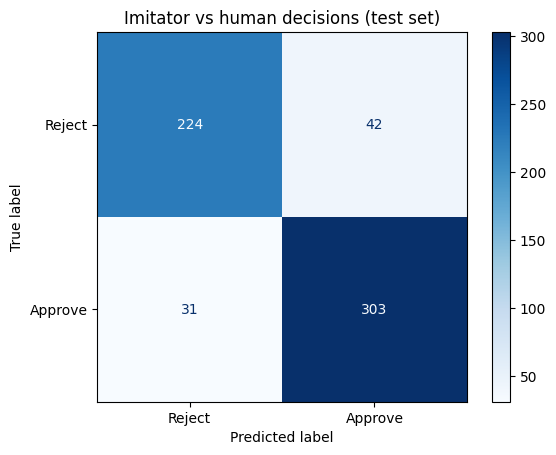

Expert-system agreement with human: 0.725


In [5]:
ConfusionMatrixDisplay.from_estimator(imitator, test_df[FEATURES], y_test,
                                      display_labels=["Reject", "Approve"], cmap="Blues")
plt.title("Imitator vs human decisions (test set)")
plt.show()

expert_approve = (test_df["expert"] == "Approve").astype(int)
print(f"Expert-system agreement with human: {accuracy_score(y_test, expert_approve):.3f}")

## Exercise 3: Explanation Facility
Expert system → fired rules. Imitation model → factor contributions (coefficient × standardized value).

In [6]:
def explain_expert(applicant, rules=RULES):
    out = infer(applicant, rules)
    f = out["facts"]
    print(f"Recommendation : {out['decision']}")
    if out["winner"] is not None:
        print(f"Deciding rule  : {out['winner'].id}: IF {out['winner'].text}")
    others = [r for r in out["fired"] if r is not out["winner"]]
    print("Other fired    :", ", ".join(f"{r.id}->{r.decision}" for r in others) or "none")
    print(f"Key facts      : credit_score={f['credit_score']:.0f}, debt_ratio={f['debt_ratio']:.2f}, "
          f"loan_to_income={f['loan_to_income']:.2f}, stable_job={bool(f['stable_job'])}")


def explain_model(x, top=3):
    # x: one-row DataFrame containing FEATURES
    scaler, clf = imitator.named_steps["scaler"], imitator.named_steps["clf"]
    contrib = pd.Series(scaler.transform(x[FEATURES])[0] * clf.coef_[0], index=FEATURES)
    p = imitator.predict_proba(x[FEATURES])[0, 1]
    print(f"Model prediction : {'Approve' if p >= 0.5 else 'Reject'} (P(approve) = {p:.2f})")
    up = contrib.nlargest(top)
    down = contrib.nsmallest(top)
    print("Towards approval :", ", ".join(f"{k} ({v:+.2f})" for k, v in up.items() if v > 0) or "none")
    print("Towards rejection:", ", ".join(f"{k} ({v:+.2f})" for k, v in down.items() if v < 0) or "none")


row = test_df.iloc[[0]]
show_cols = ["gender", "region", "income", "credit_score", "debt_ratio",
             "loan_to_income", "past_default", "collateral"]
print(row[show_cols].to_string(index=False))
print("\n--- Expert system ---")
explain_expert(row.iloc[0].to_dict())
print("\n--- Imitation model ---")
explain_model(row)
print("\nHuman decision   :", "Approve" if row["human_decision"].iloc[0] == 1 else "Reject")

gender region  income  credit_score  debt_ratio  loan_to_income  past_default  collateral
  Male  Rural    9.37         616.0       0.374           3.895             0           0

--- Expert system ---
Recommendation : Review
Deciding rule  : R9: IF DEFAULT (no other rule applies)
Other fired    : none
Key facts      : credit_score=616, debt_ratio=0.37, loan_to_income=3.90, stable_job=True

--- Imitation model ---
Model prediction : Reject (P(approve) = 0.00)
Towards approval : income (+1.12), employment_years (+0.31), past_default (+0.30)
Towards rejection: credit_score (-3.55), loan_to_income (-1.94), debt_ratio (-1.60)

Human decision   : Reject


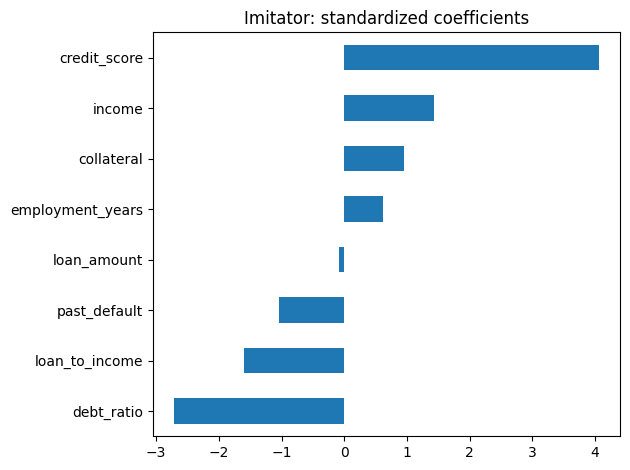

|--- credit_score <= 670.50
|   |--- debt_ratio <= 0.16
|   |   |--- credit_score <= 635.50
|   |   |   |--- loan_amount <= 11.94
|   |   |   |   |--- class: 1
|   |   |   |--- loan_amount >  11.94
|   |   |   |   |--- class: 0
|   |   |--- credit_score >  635.50
|   |   |   |--- loan_to_income <= 3.84
|   |   |   |   |--- class: 1
|   |   |   |--- loan_to_income >  3.84
|   |   |   |   |--- class: 0
|   |--- debt_ratio >  0.16
|   |   |--- loan_to_income <= 2.00
|   |   |   |--- credit_score <= 622.50
|   |   |   |   |--- class: 0
|   |   |   |--- credit_score >  622.50
|   |   |   |   |--- class: 0
|   |   |--- loan_to_income >  2.00
|   |   |   |--- debt_ratio <= 0.31
|   |   |   |   |--- class: 0
|   |   |   |--- debt_ratio >  0.31
|   |   |   |   |--- class: 0
|--- credit_score >  670.50
|   |--- debt_ratio <= 0.42
|   |   |--- credit_score <= 712.50
|   |   |   |--- debt_ratio <= 0.27
|   |   |   |   |--- class: 1
|   |   |   |--- debt_ratio >  0.27
|   |   |   |   |--- class: 1


In [7]:
# Global view: which factors matter most overall
coef = pd.Series(imitator.named_steps["clf"].coef_[0], index=FEATURES).sort_values()
coef.plot.barh(title="Imitator: standardized coefficients")
plt.tight_layout()
plt.show()

print(export_text(tree, feature_names=FEATURES, max_depth=3))

## Exercise 4: Ethical AI
Audit by **gender**, **age group** and **region**.
- **Parity gap / DI ratio:** approval-rate gap and ratio between groups (DI < 0.8 fails the 80% rule)
- **Opportunity gap:** approval-rate gap among deserving applicants (`merit = 1`)
- **Counterfactual test:** flip only gender and check whether decisions change

`Imitator + gender` is an audit-only model that is given gender as an input.

In [8]:
FEATURES_G = FEATURES + ["is_female"]
imitator_g = train_lr(train_df, FEATURES_G)

audit = test_df.copy()
audit["Human"] = audit["human_decision"]
audit["Expert system"] = (audit["expert"] == "Approve").astype(int)
audit["Imitator"] = imitator.predict(audit[FEATURES])
audit["Imitator + gender"] = imitator_g.predict(audit[FEATURES_G])

SYSTEMS = ["Human", "Expert system", "Imitator", "Imitator + gender"]
GROUPS = ["gender", "age_group", "region"]


def fairness_report(d, pred_col, group_col):
    rows = []
    for g, sub in d.groupby(group_col):
        rows.append({"group": g, "n": len(sub),
                     "approval_rate": sub[pred_col].mean(),
                     "approval_rate_of_deserving": sub.loc[sub["merit"] == 1, pred_col].mean()})
    rep = pd.DataFrame(rows).set_index("group")
    summary = {"DI ratio": rep["approval_rate"].min() / rep["approval_rate"].max(),
               "Parity gap": rep["approval_rate"].max() - rep["approval_rate"].min(),
               "Opportunity gap": rep["approval_rate_of_deserving"].max()
                                  - rep["approval_rate_of_deserving"].min()}
    return rep, summary


table = []
for s in SYSTEMS:
    for g in GROUPS:
        _, summ = fairness_report(audit, s, g)
        table.append({"system": s, "attribute": g, **summ,
                      "passes 80% rule": summ["DI ratio"] >= 0.8})
audit_table = pd.DataFrame(table)
audit_table.round(3)

,system,attribute,DI ratio,Parity gap,Opportunity gap,passes 80% rule
0,Human,gender,0.864,0.082,0.199,True
1,Human,age_group,0.840,0.095,0.072,True
2,Human,region,0.988,0.006,0.017,True
3,Expert system,gender,0.983,0.006,0.013,True
4,Expert system,age_group,0.824,0.068,0.058,True
5,Expert system,region,0.953,0.017,0.019,True
6,Imitator,gender,0.878,0.075,0.049,True
7,Imitator,age_group,0.914,0.051,0.030,True
8,Imitator,region,0.938,0.037,0.022,True
9,Imitator + gender,gender,0.875,0.075,0.141,True


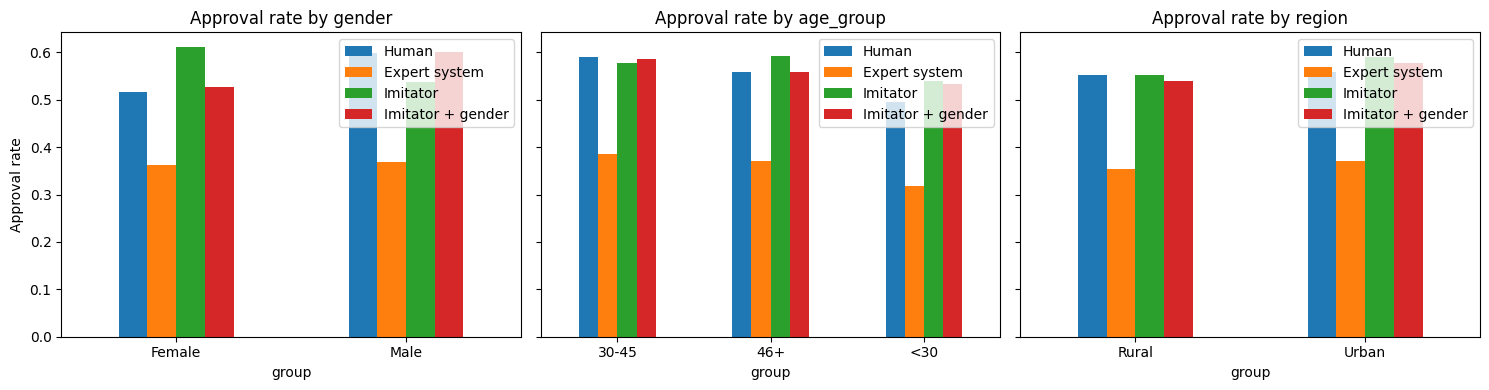

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, g in zip(axes, GROUPS):
    rates = pd.DataFrame({s: fairness_report(audit, s, g)[0]["approval_rate"] for s in SYSTEMS})
    rates.plot.bar(ax=ax, rot=0, title=f"Approval rate by {g}")
axes[0].set_ylabel("Approval rate")
plt.tight_layout()
plt.show()

In [10]:
# Counterfactual test: flip only gender, see how many decisions change
flipped = audit.copy()
flipped["is_female"] = 1 - flipped["is_female"]
changed = (imitator_g.predict(flipped[FEATURES_G]) != audit["Imitator + gender"].to_numpy()).mean()
print(f"Imitator + gender: {changed:.1%} of decisions change when only gender is flipped")
print("Expert system and Imitator do not use gender, so this is 0% by construction.")

Imitator + gender: 11.3% of decisions change when only gender is flipped
Expert system and Imitator do not use gender, so this is 0% by construction.


**Transparency check**

| System | Explains each decision? | Uses gender? |
|---|---|---|
| Human reviewers | No recorded reasons | Hidden bias (simulated) |
| Expert system | Yes, fired rules | No |
| Imitator | Yes, factor contributions | No |
| Imitator + gender | Yes, factor contributions | Yes (audit only) |

Region may still show a small gap through income, which acts as a proxy.

## Exercise 5: Testing and Comparison
Change the rules and the training examples, then compare before vs after.

### A. Modified rules
v2: R2 stricter (credit < 620), R3 relaxed (debt ratio > 0.55), new rule R10 (credit >= 700 and 5+ years employed → Approve).

In [11]:
def modify(rules, rid, **changes):
    return [replace(r, **changes) if r.id == rid else r for r in rules]


RULES_V2 = modify(RULES, "R2", text="credit_score < 620",
                  cond=lambda f: f["credit_score"] < 620)
RULES_V2 = modify(RULES_V2, "R3", text="debt_ratio > 0.55",
                  cond=lambda f: f["debt_ratio"] > 0.55)
RULES_V2 = RULES_V2 + [Rule("R10", "credit_score >= 700 AND employment_years >= 5 AND loan_to_income <= 3.5",
                            lambda f: f["credit_score"] >= 700 and f["employment_years"] >= 5
                                      and f["loan_to_income"] <= 3.5,
                            "Approve", 45)]

audit["expert_v1"] = audit["expert"]
audit["expert_v2"] = run_rules(audit, RULES_V2)

print(pd.crosstab(audit["expert_v1"], audit["expert_v2"],
                  rownames=["before (v1)"], colnames=["after (v2)"]))


def compare_rules(d, col):
    approve = (d[col] == "Approve").astype(int)
    tmp = d.assign(pred=approve)
    return {"Approve %": approve.mean(),
            "Review %": (d[col] == "Review").mean(),
            "Reject %": (d[col] == "Reject").mean(),
            "Agreement with human": (approve == d["human_decision"]).mean(),
            "Gender DI ratio": fairness_report(tmp, "pred", "gender")[1]["DI ratio"],
            "Region DI ratio": fairness_report(tmp, "pred", "region")[1]["DI ratio"]}


pd.DataFrame({"Rules v1": compare_rules(audit, "expert_v1"),
              "Rules v2": compare_rules(audit, "expert_v2")}).round(3)

after (v2)   Approve  Reject  Review
before (v1)                         
Approve          219       0       0
Reject             2     152      14
Review            19      47     147


,Rules v1,Rules v2
Approve %,0.365,0.400
Review %,0.355,0.268
Reject %,0.280,0.332
Agreement with human,0.725,0.753
Gender DI ratio,0.983,0.974
Region DI ratio,0.953,0.919


In [12]:
# One applicant whose recommendation changed, explained before and after
diff = audit[audit["expert_v1"] != audit["expert_v2"]]
if len(diff) > 0:
    a = diff.iloc[0].to_dict()
    print("v1:")
    explain_expert(a, RULES)
    print("\nv2:")
    explain_expert(a, RULES_V2)
else:
    print("No recommendation changed.")

v1:
Recommendation : Review
Deciding rule  : R9: IF DEFAULT (no other rule applies)
Other fired    : none
Key facts      : credit_score=616, debt_ratio=0.37, loan_to_income=3.90, stable_job=True

v2:
Recommendation : Reject
Deciding rule  : R2: IF credit_score < 620
Other fired    : R9->Review
Key facts      : credit_score=616, debt_ratio=0.37, loan_to_income=3.90, stable_job=True


### B. Corrected training examples
v2 relabels the training examples with the bias-free decision (`merit`) and retrains the gender-aware model.

In [13]:
train_v2 = train_df.assign(human_decision=train_df["merit"])   # re-reviewed examples
imitator_g_v2 = train_lr(train_v2, FEATURES_G)

audit["Imitator + gender (v1)"] = audit["Imitator + gender"]
audit["Imitator + gender (v2)"] = imitator_g_v2.predict(audit[FEATURES_G])


def compare_model(d, col):
    _, s = fairness_report(d, col, "gender")
    return {"Approval rate": d[col].mean(),
            "Accuracy vs human": (d[col] == d["human_decision"]).mean(),
            "Accuracy vs merit": (d[col] == d["merit"]).mean(),
            "Gender DI ratio": s["DI ratio"],
            "Gender opportunity gap": s["Opportunity gap"]}


print("Predictions changed:",
      int((audit["Imitator + gender (v1)"] != audit["Imitator + gender (v2)"]).sum()),
      "of", len(audit))
for name, m in [("v1", imitator_g), ("v2", imitator_g_v2)]:
    print(f"is_female coefficient ({name}):", round(m.named_steps["clf"].coef_[0][-1], 3))

pd.DataFrame({"Examples v1 (biased)": compare_model(audit, "Imitator + gender (v1)"),
              "Examples v2 (corrected)": compare_model(audit, "Imitator + gender (v2)")}).round(3)

Predictions changed: 48 of 600
is_female coefficient (v1): -0.844
is_female coefficient (v2): 0.229


,Examples v1 (biased),Examples v2 (corrected)
Approval rate,0.563,0.637
Accuracy vs human,0.903,0.867
Accuracy vs merit,0.875,0.902
Gender DI ratio,0.875,0.896
Gender opportunity gap,0.141,0.023


## Conclusion
- The expert system is transparent and easy to edit, but only as good as its rules.
- Imitation learning copies human patterns, including bias when sensitive inputs are used.
- Audit, explain and re-test after every change to rules or training data.